In [ ]:
#importing libraries

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,  mean_absolute_error

In [38]:
#importing lap time data
laps = pd.read_csv('data/lap_times.csv')
laps.head()

,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


In [39]:
#data exploration
print("Shape of the dataset:", laps.shape)
print("Columns in the dataset:", laps.columns)
print("Data types of the columns:", laps.dtypes)
print("Summary statistics of the dataset:\n", laps.describe())
print("Number of missing values in each column:\n", laps.isnull().sum())
print("Unique values in each column:\n", laps.nunique())

Shape of the dataset: (589081, 6)
Columns in the dataset: Index(['raceId', 'driverId', 'lap', 'position', 'time', 'milliseconds'], dtype='object')
Data types of the columns: raceId           int64
driverId         int64
lap              int64
position         int64
time            object
milliseconds     int64
dtype: object
Summary statistics of the dataset:
               raceId       driverId            lap       position  \
count  589081.000000  589081.000000  589081.000000  589081.000000   
mean      600.544465     325.796446      30.018104       9.661951   
std       434.375976     387.561736      18.407126       5.528553   
min         1.000000       1.000000       1.000000       1.000000   
25%       140.000000      16.000000      14.000000       5.000000   
50%       861.000000      48.000000      29.000000       9.000000   
75%      1003.000000     822.000000      44.000000      14.000000   
max      1144.000000     862.000000      87.000000      24.000000   

       milliseco

In [40]:
#deciding on a specific race to analyse
laps["raceId"].value_counts()

raceId
354     1649
870     1621
846     1604
869     1580
59      1558
        ... 
154      510
1092     504
203      467
79       432
1063      20
Name: count, Length: 544, dtype: int64

In [41]:
#race 354 hace most laps, so we will focus on that race for our analysis
#finding how many drivers participated in that race (24 expected)
race_354 = laps[laps["raceId"] == 354]
print("Number of drivers in race 354:", race_354["driverId"].nunique())

Number of drivers in race 354: 24


In [42]:
#data frame for race 354
race_354_df = race_354[["driverId", "lap", "position", "time", "milliseconds"]]

In [43]:
#using milliseconds column to create a new column for time in seconds
race_354_df["time_seconds"] = race_354_df["milliseconds"] / 1000

In [44]:
#examinign the distribution of lap times for race 354
race_354_df["time_seconds"].describe()

count    1649.000000
mean       80.874460
std        14.937324
min        73.851000
25%        77.043000
50%        77.919000
75%        79.692000
max       477.507000
Name: time_seconds, dtype: float64

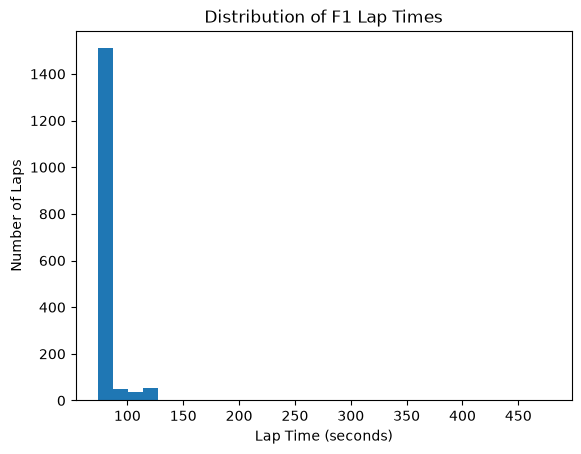

In [45]:
#max lap time is signicatly larger than the mean
#exploting the distribution of lap times for race 354
plt.hist(race_354_df["time_seconds"], bins=30)

plt.xlabel("Lap Time (seconds)")
plt.ylabel("Number of Laps")
plt.title("Distribution of F1 Lap Times")

plt.show()

In [46]:
#histogram hard to identify outliers since most values lie around the mean
#looking for the laps that are more than 2 minutes

(race_354_df["time_seconds"] > 120).sum()

np.int64(4)

In [47]:
race_354_df[race_354_df["time_seconds"] > 120]

,driverId,lap,position,time,milliseconds,time_seconds
379817,18,53,5,2:00.358,120358,120.358
380662,16,51,13,2:02.906,122906,122.906
381009,32,1,24,6:12.691,372691,372.691
381392,810,41,24,7:57.507,477507,477.507


In [48]:
#removing extreme outliers as these times are not representative of the race conditions
#decided to keep the laps that were slightly more than 2 minutes, since they are not that much more

clean_race_354_df = race_354_df[race_354_df["time_seconds"] <= 130].copy()

In [49]:
clean_race_354_df["time_seconds"].describe()

count    1647.000000
mean       80.456458
std         8.712561
min        73.851000
25%        77.043000
50%        77.918000
75%        79.677000
max       122.906000
Name: time_seconds, dtype: float64

## Investigating relationship between lap time and race progression 

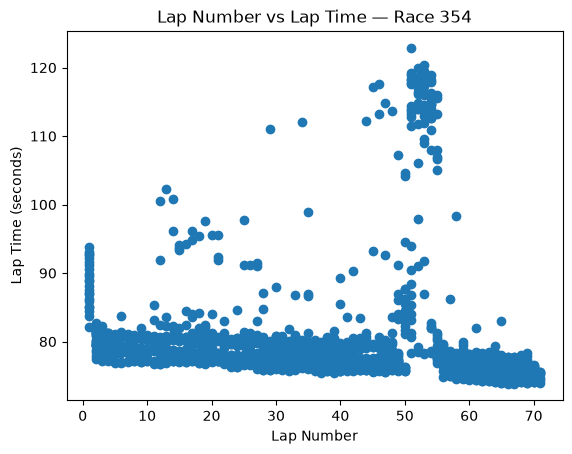

In [50]:
#scatterplot to show the relationship between lap number and lap time
plt.scatter(clean_race_354_df["lap"], clean_race_354_df["time_seconds"])
plt.xlabel("Lap Number")
plt.ylabel("Lap Time (seconds)")
plt.title("Lap Number vs Lap Time — Race 354")
plt.show()

Overall, the lap time decreases as the race goes on.

Scattered times throughout the race is expected as it is an inducation of drivers completing their pitstops.

There seems to be a jump in time around lap 50, that could be a result of yellow flags or safety car, which is common in many F1 races.

Because of these stops in normal racing, more steps need to be taken to fit a linear regression of lap time v. racing laps.

In [51]:
slow_race_df = clean_race_354_df[
    clean_race_354_df["lap"].between(48, 56)
]

slow_race_df.groupby("lap")["time_seconds"].mean()

lap
48     79.269917
49     80.395000
50     84.425217
51    102.815478
52    109.050957
53    110.457087
54    105.877609
55     88.272870
56     77.537609
Name: time_seconds, dtype: float64

In [52]:
#checking the drivers involved in the slow laps
slow_race_df.groupby("lap")["driverId"].nunique()

lap
48    24
49    24
50    23
51    23
52    23
53    23
54    23
55    23
56    23
Name: driverId, dtype: int64

Average lap times increased sharply between laps 50 and 53, reaching approximately 110.46 seconds, before returning towards normal racing pace by lap 56. This pattern suggests a race-wide interruption, potentially involving a safety car or another incident affecting multiple drivers. This is the likely scenario due to the number of drivers decreasing from 24 to 23 after lap 49, corrsponding to when lap times started increasing.

## Regression Analysis

Goal: can lap number predict lap time during an F1 race?

Because there was likely a racing incident that contributed to lap time, two regression models will be created.  

Model 1: all laps will be considered (except the two extreme outliers)
Model 2: laps 50-55 excluded since they are not represenative of normal racing laps

Using the two models, we can see how unusal racing conditions affect linear regression.

#### Model 1

In [53]:
# defining variables
X = clean_race_354_df[["lap"]]
y = clean_race_354_df["time_seconds"]

#checking correct set up of variables
print(X.shape)
print(y.shape)


(1647, 1)
(1647,)


In [54]:
#setting up train/test split
#split will be random across the drivers, this is ok for now because we are just trying to model the lap time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1317, 1)
(330, 1)
(1317,)
(330,)


In [55]:
#creating linear regression model
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

#regression coefficients
print(model.intercept_)
print(model.coef_)

79.41048967948178
[0.02979442]


The model intercept being 79.41 seconds make sense from the previous graph of lap time vs. time number, where this is the time drivers will have on their first lap of the race.

Surprising was that the slope coefficent was positive (0.03 seconds).  This would indicate that that drivers are increasing their lap times by this every lap, while the general trend shows an overall decrease.  This could be a result of driver's pit stops throughout the race, that would typically add 7-20 seconds per lap time and the safety car incident that happened near the end of the race.

In [56]:
#investigating the positive coefficient
#seeing whether the first half of the race is faster than the second half of the race based on the average lap time

clean_race_354_df.groupby(
    clean_race_354_df["lap"]<=30
)["time_seconds"].mean()

lap
False    81.041756
True     79.701025
Name: time_seconds, dtype: float64

In [57]:
#running the regression model without the probably safety car laps

#data set without suspected safety car laps
race_no_safety_car_df = clean_race_354_df[
    ~clean_race_354_df["lap"].between(48, 56)].copy()

#new variables
X = race_no_safety_car_df[["lap"]]
y = race_no_safety_car_df["time_seconds"]

In [58]:
#new regression model
X_train_no_safety_car, X_test_no_safety_car, y_train_no_safety_car, y_test_no_safety_car = train_test_split(X, y, test_size=0.2, random_state=42)

model_no_safety_car = LinearRegression()
model_no_safety_car.fit(X_train_no_safety_car, y_train_no_safety_car)

#retesting the coeefficent and intercept
print(model_no_safety_car.intercept_)
print(model_no_safety_car.coef_)

80.87080197398453
[-0.06851679]


In [59]:
print("Original model:", model.coef_[0])
print("Without safety car:", model_no_safety_car.coef_[0])

Original model: 0.029794424037893702
Without safety car: -0.0685167894673617


The initial linear regression produced a positive coefficient of 0.0298 seconds per lap, suggesting lap times increased as the race progressed. However, exploratory analysis identified an unusual race-wide slowdown between laps 50 and 55. After excluding these laps, the regression coefficient changed to −0.0685 seconds per lap, indicating a decreasing trend in lap times. This highlights the sensitivity of linear regression to unusual race conditions and the importance of exploratory data analysis before modelling.

### Model Evalutation


Mean Absolute Error (MAE) and R² were selected to evaluate the performance of the linear regression models. MAE measures the average difference between predicted and actual lap times in seconds, making it easy to interpret the model's prediction accuracy. R² measures how well the model explains variation in lap times compared to a baseline prediction. Together, these metrics provide insight into both the accuracy of the predictions and how effectively lap number explains changes in lap time.


In [64]:
#gerating predictions using the testing data without the safety car

from sklearn.metrics import mean_absolute_error


y_pred_no_safety_car = model_no_safety_car.predict(X_test_no_safety_car)

#mae and r2

mae_no_safety_car = mean_absolute_error(y_test_no_safety_car, y_pred_no_safety_car)
r2_no_safety_car = r2_score(y_test_no_safety_car, y_pred_no_safety_car)


In [62]:
#gernerating predictions using the testing data with the safety car

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [63]:
print("MAE with safety car:", mae)
print("R2 with safety car:", r2)
print("MAE without safety car:", mae_no_safety_car)
print("R2 without safety car:", r2_no_safety_car)

MAE with safety car: 5.417901196370029
R2 with safety car: -0.009881930938025807
MAE without safety car: 1.946056249247283
R2 without safety car: 0.0664235992890847


## Linear Regression Results


## Linear Regression Results

Two linear regression models were developed to predict lap time using lap number. The first model included all cleaned laps, while the second excluded laps 50–55 due to a suspected safety car period.

### Model Performance

| Metric | With Safety Car Laps | Without Safety Car Laps |
|---|---|---|
| Regression Coefficient | 0.0298 | -0.0685 |
| Mean Absolute Error (MAE) | 5.42 seconds | 1.95 seconds |
| R² Score | -0.0099 | 0.0664 |

### Interpretation

**Regression Coefficients**

The original model produced a positive coefficient, suggesting lap times increased as the race progressed. After excluding the suspected safety car laps, the coefficient became negative, indicating that lap times generally decreased throughout the race.

This demonstrates how unusual observations can influence the direction of a linear regression model.

**Mean Absolute Error (MAE)**

The MAE decreased from 5.42 seconds to 1.95 seconds, representing approximately a 64% reduction in prediction error.

However, because the models were evaluated on different datasets, this improvement may partly reflect the removal of unusually slow laps rather than an improvement in the model itself.

**R² Score**

The original model had an R² of -0.0099, meaning it performed slightly worse than a baseline prediction using the average lap time.

After removing the suspected safety car laps, the R² increased to 0.0664, indicating that lap number explained approximately 6.6% of the variation in lap times in the testing dataset.

### Overall Findings

- **Sensitivity to unusual observations:** The suspected safety car laps significantly influenced the regression coefficient and model performance.
- **Importance of data cleaning:** Investigating unusual lap times helped identify a different underlying trend.
- **Limitations of simple linear regression:** Lap number alone is not a strong predictor of lap time, as shown by the low R² values.
- **Importance of model evaluation:** A model can identify a relationship between variables without necessarily providing accurate predictions.

### Conclusion

The results suggest that lap times tend to decrease as the race progresses when the suspected safety car period is excluded. However, lap number alone explains only a small proportion of the variation in lap times.

Future models could incorporate additional variables, such as driver identity, pit stops, and race conditions, to improve prediction accuracy.
